# Email Spam Detection Using Logistic Regression

This notebook follows the structure of your existing `main.ipynb`, but replaces `RandomForestClassifier` with **Logistic Regression** and adds model evaluation. It expects a CSV named `email_spam_dataset.csv` with the columns `input` (message text) and `output` (`ham` or `spam`).

**Pipeline:** load data → inspect and clean → split data → TF-IDF text features → train Logistic Regression → evaluate → predict new messages.

## 1. Import libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

import pickle
from pathlib import Path

## 2. Load the dataset

Keep `email_spam_dataset.csv` in the same folder as this notebook, or update the path below.

In [3]:
dataset = pd.read_csv("email_spam_dataset.csv")
dataset.head()

,output,input
0,spam,Final notice: claim your laptop before your re...
1,ham,Can you help me with this task? RefH16120
2,spam,Claim your FREE holiday package before this of...
3,spam,Act now to receive your special gift voucher. ...
4,spam,WINNER ALERT: You have won laptop. Contact us ...


## 3. Inspect and prepare the data

In [4]:
print("Dataset shape:", dataset.shape)
print("\nColumns:", dataset.columns.tolist())
dataset.info()

Dataset shape: (100000, 2)

Columns: ['output', 'input']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   output  100000 non-null  object
 1   input   100000 non-null  object
dtypes: object(2)
memory usage: 1.5+ MB


In [5]:
# The notebook expects columns named input and output.
required_columns = {"input", "output"}
missing_columns = required_columns - set(dataset.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}. Expected columns: input, output")

print("Missing values:\n", dataset[["input", "output"]].isnull().sum())
print("Duplicate rows:", dataset.duplicated(subset=["input", "output"]).sum())

Missing values:
 input     0
output    0
dtype: int64
Duplicate rows: 0


In [6]:
# Remove rows without message text or label, then remove exact duplicate examples.
dataset = dataset.dropna(subset=["input", "output"]).drop_duplicates(subset=["input", "output"]).copy()
dataset["input"] = dataset["input"].astype(str)
dataset["output"] = dataset["output"].astype(str).str.strip().str.lower()

print(dataset["output"].value_counts())
print("Cleaned dataset shape:", dataset.shape)

output
spam    50000
ham     50000
Name: count, dtype: int64
Cleaned dataset shape: (100000, 2)


/var/folders/kb/5k24n_390rb3g3xwdn5nfft80000gn/T/ipykernel_3262/1871723513.py:3: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  dataset["input"] = dataset["input"].astype(str)
/var/folders/kb/5k24n_390rb3g3xwdn5nfft80000gn/T/ipykernel_3262/18

## 4. Explore the class distribution

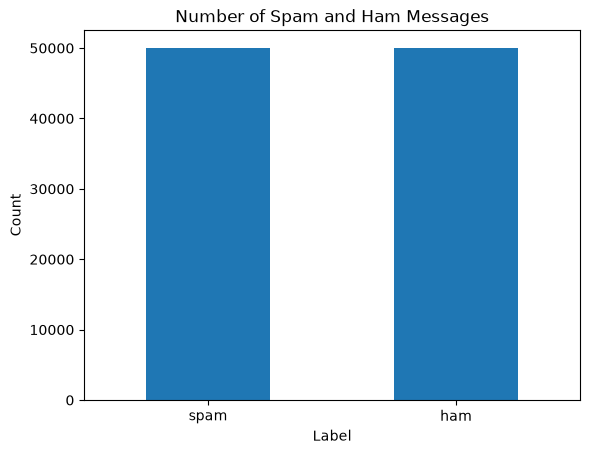

In [7]:
dataset["output"].value_counts().plot(kind="bar", rot=0)
plt.title("Number of Spam and Ham Messages")
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()

## 5. Separate features and labels

Here, `ham` means a legitimate message and `spam` means an unwanted message. We map `ham` to `not_spam` to keep the same label style as your original notebook.

In [8]:
dataset["output"] = dataset["output"].map({"ham": "not_spam", "spam": "spam"})
dataset = dataset.dropna(subset=["output"])

inputData = dataset["input"]
outputData = dataset["output"]
print(outputData.value_counts())

output
spam        50000
not_spam    50000
Name: count, dtype: int64


/var/folders/kb/5k24n_390rb3g3xwdn5nfft80000gn/T/ipykernel_3262/178961498.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  dataset["output"] = dataset["output"].map({"ham": "not_spam", "spam": "spam"})


## 6. Split into training and test data

The test set is held out so that evaluation measures performance on messages the model did not train on. `stratify` preserves the label proportions in both sets.

In [9]:
inputDataTrain, inputDataTest, outputDataTrain, outputDataTest = train_test_split(
    inputData,
    outputData,
    test_size=0.2,
    random_state=42,
    stratify=outputData
)

print("Training examples:", len(inputDataTrain))
print("Test examples:", len(inputDataTest))

Training examples: 80000
Test examples: 20000


## 7. Convert message text to TF-IDF features

In [11]:
vectorizor = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), max_features=20000)

# Fit only on training text to avoid data leakage.
conversionTrain = vectorizor.fit_transform(inputDataTrain)
conversionTest = vectorizor.transform(inputDataTest)

print("Training matrix shape:", conversionTrain.shape)
print("Test matrix shape:", conversionTest.shape)

Training matrix shape: (80000, 20000)
Test matrix shape: (20000, 20000)


## 8. Train the Logistic Regression model

In [12]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(conversionTrain, outputDataTrain)
print("Model training complete.")

Model training complete.


/Users/aftab/Desktop/ML/.venv/lib/python3.15/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


## 9. Evaluate the model

In [13]:
prediction = model.predict(conversionTest)

print(f"Accuracy:  {accuracy_score(outputDataTest, prediction):.4f}")
print(f"Precision: {precision_score(outputDataTest, prediction, pos_label='spam', zero_division=0):.4f}")
print(f"Recall:    {recall_score(outputDataTest, prediction, pos_label='spam', zero_division=0):.4f}")
print(f"F1-score:  {f1_score(outputDataTest, prediction, pos_label='spam', zero_division=0):.4f}")
print("\nClassification report:\n")
print(classification_report(outputDataTest, prediction, zero_division=0))

Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-score:  1.0000

Classification report:

              precision    recall  f1-score   support

    not_spam       1.00      1.00      1.00     10000
        spam       1.00      1.00      1.00     10000

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000



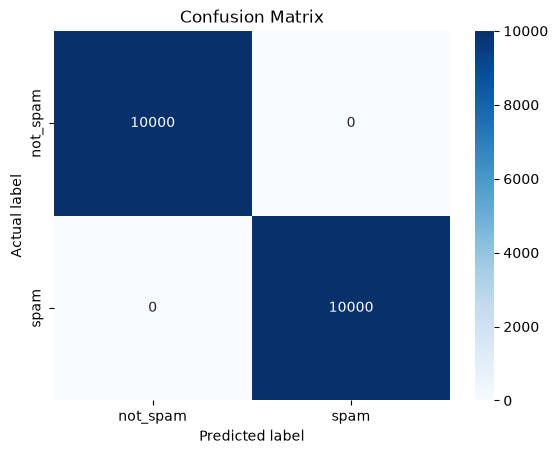

In [14]:
labels = ["not_spam", "spam"]
cm = confusion_matrix(outputDataTest, prediction, labels=labels)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Confusion Matrix")
plt.show()

## 10. Predict a new message

In [15]:
new_msg = ["You have been chosen for an exclusive cash bonus of $1,000. Claim your reward now!"]
n_conversion = vectorizor.transform(new_msg)
prediction_new = model.predict(n_conversion)[0]
probabilities = model.predict_proba(n_conversion)[0]
spam_index = list(model.classes_).index("spam")
spam_probability = probabilities[spam_index]

print("Prediction:", prediction_new)
print(f"Estimated spam probability: {spam_probability:.2%}")

Prediction: spam
Estimated spam probability: 99.99%


## 11. Create a reusable prediction function

In [16]:
def predict_spam(message):
    """Classify one message and return its label and estimated spam probability."""
    message_vector = vectorizor.transform([message])
    predicted_label = model.predict(message_vector)[0]
    class_probabilities = model.predict_proba(message_vector)[0]
    spam_probability = class_probabilities[list(model.classes_).index("spam")]
    return {
        "prediction": "spam" if predicted_label == "spam" else "not_spam",
        "spam_probability": round(float(spam_probability), 4)
    }

# Try your own message
predict_spam("Congratulations! You won a free prize. Click here to claim it.")

{'prediction': 'spam', 'spam_probability': 0.9833}

## 12. Test multiple messages

In [17]:
test_messages = [
    "Congratulations! You have won a free gift. Claim now!",
    "Hi, are we still meeting for lunch tomorrow?",
    "Your account has been selected for a cash reward. Reply now."
]

for message in test_messages:
    print("Message:", message)
    print("Result:", predict_spam(message))
    print("-" * 60)

Message: Congratulations! You have won a free gift. Claim now!
Result: {'prediction': 'spam', 'spam_probability': 0.9975}
------------------------------------------------------------
Message: Hi, are we still meeting for lunch tomorrow?
Result: {'prediction': 'not_spam', 'spam_probability': 0.0071}
------------------------------------------------------------
Message: Your account has been selected for a cash reward. Reply now.
Result: {'prediction': 'spam', 'spam_probability': 0.9982}
------------------------------------------------------------


## 13. Export the trained model for sharing

This section saves the **trained Logistic Regression model and its fitted TF-IDF vectorizer together in one `.pkl` file**. The vectorizer is required because new messages must be converted using the same vocabulary and TF-IDF weights used during training.

After running the export cell, share `spam_detection_model.pkl` with anyone who wants to try the model. They do not need your training CSV, but they do need Python and compatible versions of `scikit-learn`. Only load pickle files from a trusted source because loading an untrusted pickle can execute arbitrary code.

In [18]:
# Save the model and vectorizer together in one pickle file.
MODELS_DIR = Path("models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_FILE = MODELS_DIR / "spam_detection_model.pkl"

model_package = {
    "model": model,
    "vectorizer": vectorizor,
    "labels": list(model.classes_),
    "positive_label": "spam",
    "model_type": "LogisticRegression + TfidfVectorizer",
}

with MODEL_FILE.open("wb") as file:
    pickle.dump(model_package, file, protocol=pickle.HIGHEST_PROTOCOL)

print(f"Model exported to: {MODEL_FILE.resolve()}")
print(f"File size: {MODEL_FILE.stat().st_size / 1024:.1f} KB")

Model exported to: /Users/aftab/Desktop/ML/Projects/Spam Detection/models/spam_detection_model.pkl
File size: 919.5 KB


### How another person can use the exported model

Send them `spam_detection_model.pkl` and the following small Python script (or copy this code into their project). They do **not** need to retrain the model or have the original dataset.

In [ ]:
# Example inference code for the person receiving the model.
# Save this code as use_spam_model.py in the same folder as spam_detection_model.pkl.

import pickle

with open("models/spam_detection_model.pkl", "rb") as file:
    package = pickle.load(file)

loaded_model = package["model"]
loaded_vectorizer = package["vectorizer"]


def predict_spam(message: str):
    message_features = loaded_vectorizer.transform([message])
    predicted_label = loaded_model.predict(message_features)[0]
    probabilities = loaded_model.predict_proba(message_features)[0]
    spam_index = list(loaded_model.classes_).index("spam")

    return {
        "prediction": "spam" if predicted_label == "spam" else "not_spam",
        "spam_probability": round(float(probabilities[spam_index]), 4),
    }

if __name__ == "__main__":
    sample = "Congratulations! You won a free prize. Click here to claim it."
    print(predict_spam(sample))

{'prediction': 'not_spam', 'spam_probability': 0.3571}


### Requirements for the person receiving the model

Install compatible dependencies in their Python environment:

```bash
pip install scikit-learn
```

Then run:

```bash
python use_spam_model.py
```

**Important:** the probability is the model's estimated probability, not a guarantee. Model quality depends on the training data; synthetic or repetitive training messages may not reflect real-world email performance. Pickle files should only be loaded from trusted sources.

## Summary and limitations

- TF-IDF converts text into numeric features; Logistic Regression learns to classify those features.
- Accuracy alone is not enough for spam detection. Review precision, recall, F1-score, and the confusion matrix.
- These results depend on the quality and representativeness of your dataset. If the dataset is synthetic or very repetitive, scores may look much better than real-world performance. Test with realistic, unseen messages before drawing conclusions.
- The export section saves the trained model and fitted TF-IDF vectorizer together in `spam_detection_model.pickle`, so the artifact can be shared without the training dataset.